In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

sns.set_theme(style="whitegrid")

In [3]:
train = pd.read_csv("../data/clean/train.csv")
test = pd.read_csv("../data/clean/test.csv")

print("Train:", train.shape)
print("Test:", test.shape)

display(train.head())

Train: (3592, 15)
Test: (898, 15)


,Listing ID,Location,Latitude,Longitude,Price,Area,Price_per_m2,Log_Price_per_m2,Width,Length,Bedrooms,Floors,Position,Dist_BenThanh_km,Dist_Metro_km
0,1133455.0,"Phường Thông Tây Hội,TP. Hồ Chí Minh(Mới)",10.834083,106.663250,7200.0,68.0,105.882353,4.662329,4.0,17.0,3.0,2.0,Trong hẻm,7.829292,7.101193
1,1368370.0,"Phường Thủ Dầu Một,TP. Hồ Chí Minh(Mới)",10.972671,106.671483,60000.0,880.0,68.181818,4.222178,15.0,60.0,4.0,3.0,Đường chính,22.445561,17.798046
2,1533116.0,"Phường Phú Lợi,TP. Hồ Chí Minh(Mới)",10.984924,106.697473,2580.0,128.0,20.156250,3.003514,5.0,26.0,1.0,1.0,Đường chính,23.620501,17.190781
3,1542633.0,"Đường Kênh 19/5,Phường Tây Thạnh,TP. Hồ Chí Mi...",10.808290,106.613922,5250.0,36.0,145.833333,4.982464,4.0,9.0,3.0,4.0,Trong hẻm,10.008940,10.033261
4,1407728.0,"Phường Bình Trị Đông,TP. Hồ Chí Minh(Mới)",10.778985,106.597159,5530.0,52.0,106.346154,4.666699,4.0,13.0,4.0,3.0,Trong hẻm,11.038915,10.987279


In [4]:
features = [
    "Area",
    "Width",
    "Length",
    "Bedrooms",
    "Floors",
    "Position",
    "Dist_BenThanh_km",
    "Dist_Metro_km"
]

target = "Log_Price_per_m2"

X_train = train[features].copy()
X_test = test[features].copy()

y_train = train[target]
y_test = test[target]

In [5]:
X_train = pd.get_dummies(
    X_train,
    columns=["Position"],
    drop_first=True,
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    columns=["Position"],
    drop_first=True,
    dtype=int
)

X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

print("Số thuộc tính:", len(X_train.columns))

Số thuộc tính: 9


In [6]:
X_train_ols = sm.add_constant(X_train, has_constant="add")
X_test_ols = sm.add_constant(X_test, has_constant="add")

model_ols = sm.OLS(y_train, X_train_ols).fit()

pred_ols = model_ols.predict(X_test_ols)

print(model_ols.summary())

                            OLS Regression Results                            
Dep. Variable:       Log_Price_per_m2   R-squared:                       0.677
Model:                            OLS   Adj. R-squared:                  0.676
Method:                 Least Squares   F-statistic:                     833.3
Date:                Sat, 14 Nov 2026   Prob (F-statistic):               0.00
Time:                        19:11:14   Log-Likelihood:                -1493.5
No. Observations:                3592   AIC:                             3007.
Df Residuals:                    3582   BIC:                             3069.
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                    5.1127 

In [7]:
model_rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

model_rf.fit(X_train, y_train)

pred_rf = model_rf.predict(X_test)

In [8]:
results = pd.DataFrame({
    "Mo_hinh": ["OLS", "Random Forest"],
    "R2": [
        r2_score(y_test, pred_ols),
        r2_score(y_test, pred_rf)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, pred_ols)),
        np.sqrt(mean_squared_error(y_test, pred_rf))
    ],
    "MAE": [
        mean_absolute_error(y_test, pred_ols),
        mean_absolute_error(y_test, pred_rf)
    ]
})

display(results)

,Mo_hinh,R2,RMSE,MAE
0,OLS,0.633137,0.398320,0.292343
1,Random Forest,0.740740,0.334848,0.244274


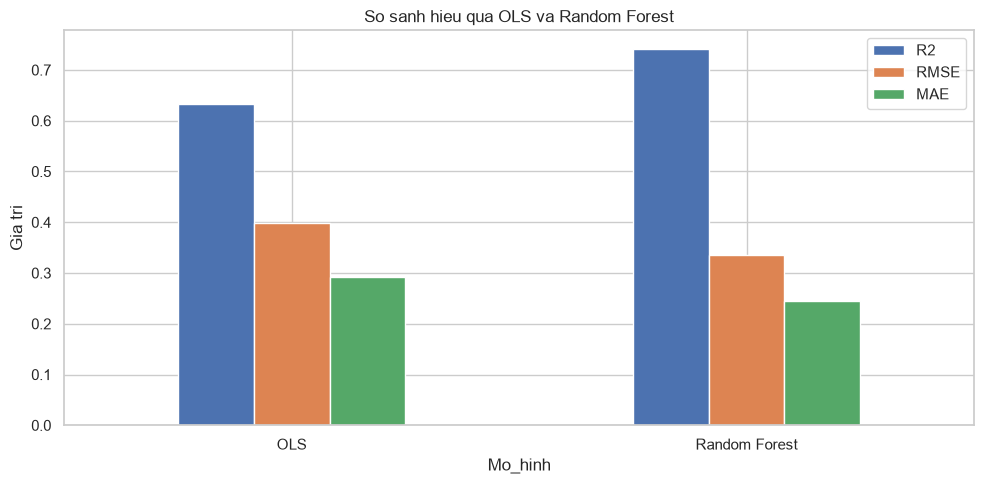

In [9]:
results.set_index("Mo_hinh")[["R2", "RMSE", "MAE"]].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("So sanh hieu qua OLS va Random Forest")
plt.ylabel("Gia tri")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [11]:
from pathlib import Path

results.to_csv(
    "../report/model_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Đã lưu kết quả so sánh mô hình!")

Đã lưu kết quả so sánh mô hình!
